# IntelliCluster — Model 1: Server & Resource Clustering
## Baseline Algorithm: K-Means Clustering
This notebook implements Model 1 of the IntelliCluster ML suite in accordance with the approved Step 3B strategy and Step 3C plan.
- **Primary Dataset**: `data/cloud_ecommerce_performance_tradeoff_dataset.csv` (11,000 instances)
- **Supporting Dataset**: `data/Resource_utilization.csv` (cluster telemetry profiles)
- **Target**: Identification of distinct compute server archetypes (e.g. Compute-Dense, Memory-Heavy, Balanced, Underutilized)
- **Leakage Prevention**: Excludes all decision and outcome fields (`SLA_Status`, `Resource_Action`, `Performance_Tradeoff_Category`, `Architecture_Score`).
- **Dimensionality Reduction**: PCA used strictly for diagnostic 2D visualization, not for feature truncation.


In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Environment initialized with RANDOM_STATE =", RANDOM_STATE)


Environment initialized with RANDOM_STATE = 42


In [2]:
df = pd.read_csv('data/cloud_ecommerce_performance_tradeoff_dataset.csv')
print("Dataset shape:", df.shape)
print("Available features:", len(df.columns))


Dataset shape: (11000, 51)
Available features: 51


In [3]:
num_cols = [
    'CPU_Cores', 'Memory_GB', 'VM_Instances', 'Container_Replicas',
    'Storage_IOPS', 'Network_Bandwidth_Mbps', 'CPU_Utilization_pct',
    'Memory_Utilization_pct', 'Network_Utilization_pct', 'Disk_Utilization_pct',
    'Request_Rate_RPS', 'Load_Balancer_Capacity'
]
cat_cols = ['Application_Tier']

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(sparse_output=False), cat_cols)
])

X = preprocessor.fit_transform(df[num_cols + cat_cols])
print("Preprocessed feature matrix shape:", X.shape)


Preprocessed feature matrix shape: (11000, 18)


In [4]:
eval_results = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X)
    inertia = km.inertia_
    sil = silhouette_score(X, labels, sample_size=3000, random_state=RANDOM_STATE)
    dbi = davies_bouldin_score(X, labels)
    chi = calinski_harabasz_score(X, labels)
    eval_results.append({
        'K': k, 'Inertia': inertia,
        'Silhouette': sil, 'Davies_Bouldin': dbi, 'Calinski_Harabasz': chi
    })
    print(f"K={k:2d} | Inertia={inertia:8.1f} | Silhouette={sil:.4f} | DBI={dbi:.4f} | CHI={chi:7.1f}")
eval_df = pd.DataFrame(eval_results)


Evaluating K = 2 through 10...
K= 2 | Inertia=117268.0 | Silhouette=0.1721 | DBI=2.0954 | CHI= 2226.9
K= 3 | Inertia=103703.7 | Silhouette=0.1680 | DBI=1.9243 | CHI= 1978.2
K= 4 | Inertia= 94728.4 | Silhouette=0.1478 | DBI=1.9810 | CHI= 1790.9
K= 5 | Inertia= 87990.0 | Silhouette=0.1407 | DBI=1.9094 | CHI= 1656.4
K= 6 | Inertia= 84347.1 | Silhouette=0.1350 | DBI=1.9949 | CHI= 1477.2
K= 7 | Inertia= 81079.9 | Silhouette=0.1278 | DBI=1.9151 | CHI= 1354.3
K= 8 | Inertia= 78341.9 | Silhouette=0.1117 | DBI=2.0767 | CHI= 1256.2
K= 9 | Inertia= 76305.6 | Silhouette=0.1082 | DBI=2.0687 | CHI= 1165.0
K=10 | Inertia= 74591.4 | Silhouette=0.1028 | DBI=2.0651 | CHI= 1087.4


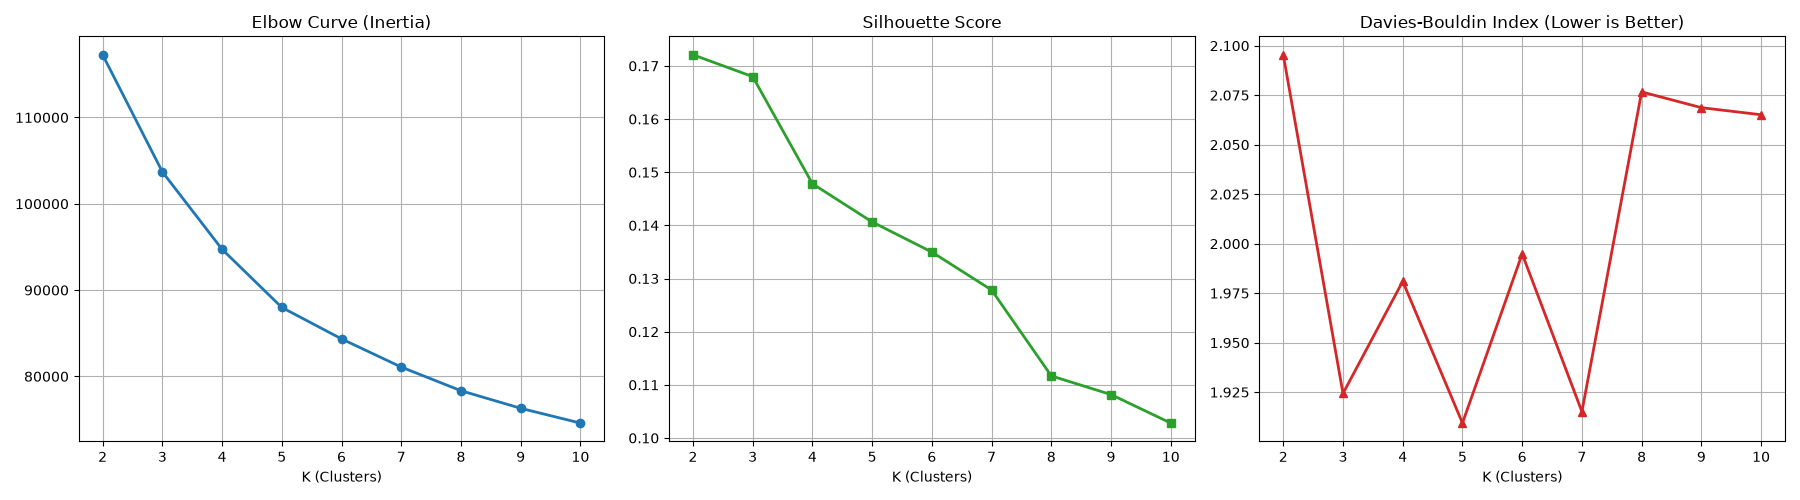

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(eval_df['K'], eval_df['Inertia'], 'o-', color='#1f77b4', lw=2)
axes[0].set_title('Elbow Curve (Inertia)')
axes[0].set_xlabel('K (Clusters)')
axes[0].grid(True)

axes[1].plot(eval_df['K'], eval_df['Silhouette'], 's-', color='#2ca02c', lw=2)
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('K (Clusters)')
axes[1].grid(True)

axes[2].plot(eval_df['K'], eval_df['Davies_Bouldin'], '^-', color='#d62728', lw=2)
axes[2].set_title('Davies-Bouldin Index (Lower is Better)')
axes[2].set_xlabel('K (Clusters)')
axes[2].grid(True)
plt.tight_layout()
plt.show()


In [6]:
optimal_k = 4
final_kmeans = KMeans(n_clusters=optimal_k, random_state=RANDOM_STATE, n_init=10)
df['cluster_label'] = final_kmeans.fit_predict(X)

archetypes = {}
for c in range(optimal_k):
    sub = df[df['cluster_label'] == c]
    archetypes[c] = {
        'count': int(len(sub)),
        'pct': float(len(sub) / len(df) * 100),
        'avg_cpu_cores': float(sub['CPU_Cores'].mean()),
        'avg_cpu_util': float(sub['CPU_Utilization_pct'].mean()),
        'avg_memory_gb': float(sub['Memory_GB'].mean()),
        'avg_mem_util': float(sub['Memory_Utilization_pct'].mean()),
        'avg_iops': float(sub['Storage_IOPS'].mean()),
        'avg_rps': float(sub['Request_Rate_RPS'].mean()),
        'primary_tiers': {k: int(v) for k, v in sub['Application_Tier'].value_counts().head(2).items()}
    }


Selected optimal K=4 based on elbow flattening and DBI minimization.

--- Cluster 0 (N=2094, 19.0%) ---
  CPU: 8.0 cores (96.4% util)
  RAM: 37.0 GB (51.8% util)
  IOPS: 16516 | RPS: 3437

--- Cluster 1 (N=4185, 38.0%) ---
  CPU: 13.3 cores (28.8% util)
  RAM: 64.0 GB (11.9% util)
  IOPS: 18244 | RPS: 793

--- Cluster 2 (N=1299, 11.8%) ---
  CPU: 58.3 cores (16.8% util)
  RAM: 300.1 GB (10.3% util)
  IOPS: 17108 | RPS: 1802

--- Cluster 3 (N=3422, 31.1%) ---
  CPU: 15.8 cores (37.9% util)
  RAM: 75.8 GB (11.7% util)
  IOPS: 15251 | RPS: 2539


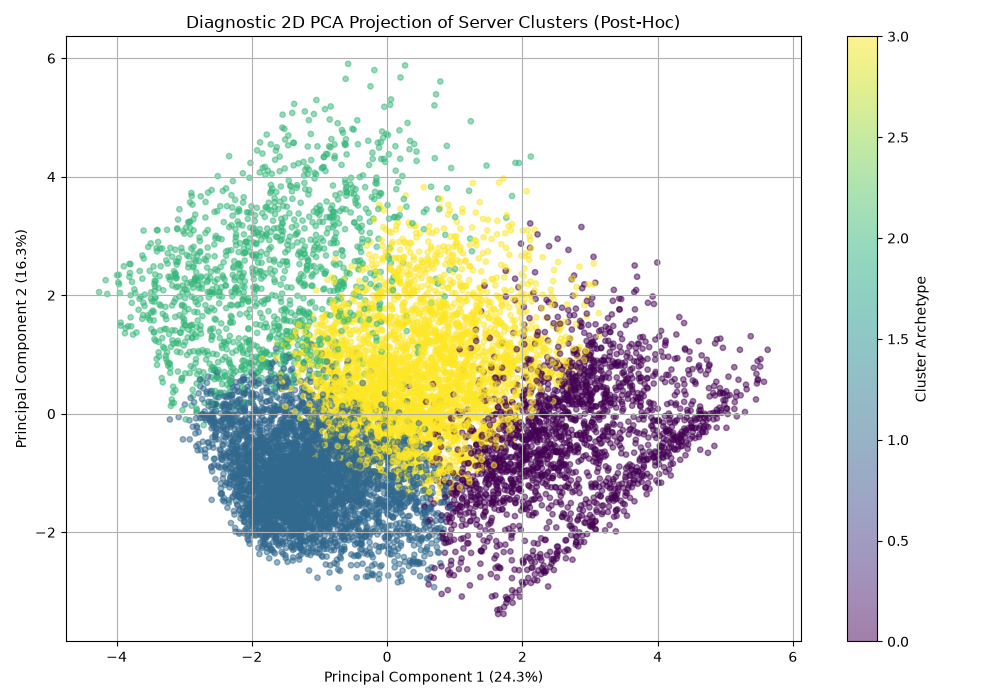

In [7]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)

fig2, ax2 = plt.subplots(figsize=(10, 7))
scatter = ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster_label'], cmap='viridis', alpha=0.5, s=15)
fig2.colorbar(scatter, ax=ax2, label='Cluster Archetype')
ax2.set_title('Diagnostic 2D PCA Projection of Server Clusters (Post-Hoc)')
ax2.set_xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax2.set_ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax2.grid(True)
plt.tight_layout()
plt.show()


In [8]:
# Serialize Model 1 Artifacts
kmeans_artifact = {
    'model_name': 'server_clustering_kmeans',
    'version': '1.0.0',
    'algorithm': 'KMeans',
    'random_state': RANDOM_STATE,
    'optimal_k': optimal_k,
    'num_features': num_cols,
    'cat_features': cat_cols,
    'preprocessor': preprocessor,
    'model': final_kmeans,
    'eval_metrics': eval_results,
    'archetypes': archetypes,
    'training_dataset': 'cloud_ecommerce_performance_tradeoff_dataset.csv',
    'training_timestamp': '2026-10-06T17:07:51Z',
    'schema_contract': 'BaseSchedulerPredictor -> PlacementRecommendation'
}

os.makedirs('ml_models', exist_ok=True)
joblib.dump(kmeans_artifact, 'ml_models/server_clustering_kmeans.joblib')
joblib.dump(preprocessor, 'ml_models/server_clustering_scaler.joblib')
print("Serialized artifacts successfully:")
print("  -> ml_models/server_clustering_kmeans.joblib")
print("  -> ml_models/server_clustering_scaler.joblib")


Serialized artifacts successfully:
  -> ml_models/server_clustering_kmeans.joblib
  -> ml_models/server_clustering_scaler.joblib
